# MathBERT: Training, Model Selection and Evaluation

## 1. Introduction

This notebook studies `tbs17/MathBERT-custom`, a model pretrained on mathematical texts with its own vocabulary, for binary answerability classification of mathematical word problems. Labels are **ANSWERABLE = 0** and **UNANSWERABLE = 1**; UNANSWERABLE is the positive class for precision, recall and F1. The task is to identify sufficient information, not to calculate the solution.

The notebook documents five completed MathBERT training runs, their selection using SUM validation, and the saved results of selected Run 04 on SUM test and the external UMWP benchmark. It reads existing artifacts only: no training, model loading or new evaluation. Use **Run All** from the project root or `notebooks/`; required analysis packages are pandas, matplotlib and Jupyter/IPython.

In [1]:
# Trainer logs its training summary before evaluate() is called again.
# Separate events by that boundary, not by epoch: the restored model's
# evaluation inherits the last training epoch in Trainer state.
from pathlib import Path
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/12_train_mathbert_run01.py').is_file() and (p / 'results/mathbert').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')
RESULTS_DIR = PROJECT_ROOT / 'results/mathbert'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
METRICS = ['eval_accuracy', 'eval_precision', 'eval_recall', 'eval_f1']
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

def read_json(path):
    with path.open(encoding='utf-8') as handle:
        return json.load(handle)

def load_run(directory):
    report = read_json(directory / 'validation_metrics.json')
    history = pd.read_csv(directory / 'training_history.csv')
    metadata = report['configuration']
    config_path = directory / 'config.json'
    if config_path.is_file():
        config = read_json(config_path)
        for key in config.keys() & metadata.keys():
            if config[key] != metadata[key]:
                raise ValueError(f'{directory.name}: conflicting configuration field {key}')
        config = {**metadata, **config}
        config_source = 'config.json + validation_metrics.json'
    elif directory.name == 'run_01':
        config = metadata.copy()
        config_source = 'validation_metrics.json (no config.json)'
    else:
        raise FileNotFoundError(config_path)
    required = {'epoch', 'step', 'loss', 'eval_loss', *METRICS, 'train_runtime'}
    if not required.issubset(history.columns):
        raise ValueError(f'{directory.name}: missing history columns {required - set(history)}')
    summaries = history.index[history['train_runtime'].notna()]
    if len(summaries) != 1:
        raise ValueError(f'{directory.name}: expected exactly one training-summary event')
    boundary = summaries[0]
    epoch_events = history.loc[history.index < boundary]
    validation = epoch_events.loc[epoch_events['eval_f1'].notna()].copy()
    training = epoch_events.loc[epoch_events['loss'].notna()].copy()
    restored = history.loc[(history.index > boundary) & history['eval_f1'].notna()]
    if validation.empty or training.empty or len(restored) != 1:
        raise ValueError(f'{directory.name}: unexpected training/evaluation event structure')
    if validation['epoch'].duplicated().any() or training['epoch'].duplicated().any():
        raise ValueError(f'{directory.name}: ambiguous repeated epoch events')
    checkpoint_step = int(report['best_checkpoint'].replace('\\', '/').rsplit('checkpoint-', 1)[1])
    candidates = validation.loc[validation['step'].eq(checkpoint_step)]
    if len(candidates) != 1:
        raise ValueError(f'{directory.name}: best checkpoint has no unique epoch event')
    best = candidates.iloc[0]
    checkpoint_f1 = report['best_checkpoint_validation_f1']
    if not math.isclose(best['eval_f1'], checkpoint_f1, abs_tol=1e-12, rel_tol=0):
        raise ValueError(f'{directory.name}: checkpoint F1 and epoch event disagree')
    if not math.isclose(validation['eval_f1'].max(), checkpoint_f1, abs_tol=1e-12, rel_tol=0):
        raise ValueError(f'{directory.name}: recorded checkpoint is not a maximum-F1 event')
    for metric in ['eval_loss', *METRICS]:
        if not math.isclose(restored.iloc[0][metric], report['best_validation_metrics'][metric], abs_tol=1e-12, rel_tol=0):
            raise ValueError(f'{directory.name}: restored evaluation and JSON disagree')
    return {'config': config, 'config_source': config_source, 'report': report, 'training': training, 'validation': validation, 'best': best, 'restored': restored.iloc[0], 'checkpoint_f1': checkpoint_f1}
run_directories = sorted((p for p in RESULTS_DIR.glob('run_*') if p.is_dir()))
expected_runs = {f'run_{i:02d}' for i in range(1, 6)}
if {p.name for p in run_directories} != expected_runs:
    raise ValueError('Expected the five MathBERT runs, run_01 through run_05.')
runs = {p.name: load_run(p) for p in run_directories}
run_labels = {name: f"Run {int(name.split('_')[1]):02d}" for name in runs}
print(f'{len(runs)} MathBERT runs loaded from {RESULTS_DIR.relative_to(PROJECT_ROOT)}.')

5 MathBERT runs loaded from results\mathbert.


## 2. Experiment Configuration

The five runs explored different learning rates and epoch budgets to improve validation performance. Configurations are loaded from each run's `config.json` and the metadata in `validation_metrics.json`; the best epoch is identified by matching the saved checkpoint step to the original validation event. Missing or contradictory information is not silently filled in.

In [2]:
configuration_rows = []
for name, run in runs.items():
    c = run['config']
    configuration_rows.append({'Run': run_labels[name], 'Learning rate': c['learning_rate'], 'Maximum epochs': c['max_epochs'], 'Completed epochs': int(run['training']['epoch'].max()), 'Best epoch': int(run['best']['epoch']), 'Warmup steps': c['warmup_steps']})
configuration_table = pd.DataFrame(configuration_rows).set_index('Run')
display(configuration_table.style.format({'Learning rate': '{:.0e}'}))
shared_keys = ['model_name', 'max_length', 'batch_size', 'weight_decay', 'warmup_ratio', 'random_seed', 'data_seed', 'gradient_accumulation_steps', 'optimizer', 'scheduler', 'early_stopping_patience', 'torch_version', 'transformers_version']
shared = {}
for key in shared_keys:
    values = [r['config'][key] for r in runs.values()]
    if any((value != values[0] for value in values)):
        raise ValueError(f'Shared setting differs across runs: {key}')
    shared[key] = values[0]
if shared['model_name'] != 'tbs17/MathBERT-custom':
    raise ValueError('Unexpected model in the MathBERT artifacts.')
display(Markdown(f"All runs use **{shared['model_name']}**, train/evaluation batch size **{shared['batch_size']}**, maximum input length **{shared['max_length']} tokens**, weight decay **{shared['weight_decay']}**, warmup ratio **{shared['warmup_ratio']}**, seed/data seed **{shared['random_seed']}/{shared['data_seed']}**, gradient accumulation **{shared['gradient_accumulation_steps']}**, **{shared['optimizer']}** and a **{shared['scheduler']}** scheduler. The training scripts use dynamic padding, with validation, logging and checkpoint saving after each epoch. The highest binary validation F1 selects the checkpoint; early stopping uses patience **{shared['early_stopping_patience']}** and threshold 0. The best checkpoint is restored at the end; at most two checkpoints are retained. Reports record PyTorch **{shared['torch_version']}** and Transformers **{shared['transformers_version']}**."))
display(Markdown('Runs 01 and 02 vary the learning rate with the same seven-epoch budget. Run 03 tests the higher learning rate with five epochs; Run 04 retains that learning rate and extends the budget to seven epochs. Run 05 increases the learning rate again. Changing the epoch budget also changes warmup and the linear learning-rate schedule: Run 04 is therefore not simply a continuation of Run 03.'))

,Learning rate,Maximum epochs,Completed epochs,Best epoch,Warmup steps
Run,,,,,
Run 01,3e-05,7,7,7,559
Run 02,2e-05,7,7,5,559
Run 03,4e-05,5,5,4,399
Run 04,4e-05,7,7,5,559
Run 05,5e-05,7,4,2,559


All runs use **tbs17/MathBERT-custom**, train/evaluation batch size **32**, maximum input length **256 tokens**, weight decay **0.01**, warmup ratio **0.05**, seed/data seed **42/42**, gradient accumulation **1**, **adamw_torch** and a **linear** scheduler. The training scripts use dynamic padding, with validation, logging and checkpoint saving after each epoch. The highest binary validation F1 selects the checkpoint; early stopping uses patience **2** and threshold 0. The best checkpoint is restored at the end; at most two checkpoints are retained. Reports record PyTorch **2.11.0+cu128** and Transformers **5.22.2**.

Runs 01 and 02 vary the learning rate with the same seven-epoch budget. Run 03 tests the higher learning rate with five epochs; Run 04 retains that learning rate and extends the budget to seven epochs. Run 05 increases the learning rate again. Changing the epoch budget also changes warmup and the linear learning-rate schedule: Run 04 is therefore not simply a continuation of Run 03.

## 3. Validation Results

The shared table presents the original validation of each run's best checkpoint. Precision, recall and F1 refer to **UNANSWERABLE**; predictions use argmax, with `zero_division=0` for undefined ratios. The primary selection criterion is the saved **best-checkpoint F1**. Post-training reevaluation after restoration is treated separately and is not an additional training epoch.

In [3]:
selected_run = max(runs, key=lambda name: runs[name]['checkpoint_f1'])
validation_rows = []
for name, run in runs.items():
    best = run['best']
    validation_rows.append({'Run': run_labels[name], 'Best epoch': int(best['epoch']), 'Accuracy': best['eval_accuracy'], 'Precision (UNANSWERABLE)': best['eval_precision'], 'Recall (UNANSWERABLE)': best['eval_recall'], 'F1 (UNANSWERABLE)': run['checkpoint_f1']})
validation_table = pd.DataFrame(validation_rows).set_index('Run')
display(validation_table.style.format({c: '{:.6f}' for c in validation_table.columns[1:]}).set_properties(subset=pd.IndexSlice[[run_labels[selected_run]], :], **{'font-weight': 'bold'}))
reevaluations = pd.DataFrame([{'Run': run_labels[name], 'Checkpoint epoch': int(run['best']['epoch']), 'Checkpoint F1': run['checkpoint_f1'], 'Post-restoration F1': run['report']['best_validation_metrics']['eval_f1'], 'Difference': run['report']['best_validation_metrics']['eval_f1'] - run['checkpoint_f1']} for name, run in runs.items()]).set_index('Run')
discrepancies = reevaluations.loc[reevaluations['Difference'].abs() > 1e-12]
if not discrepancies.empty:
    display(Markdown('**Post-restoration discrepancies:**'))
    display(discrepancies.style.format(precision=9))
else:
    display(Markdown('For all five runs, saved checkpoint F1 agrees with reevaluation after restoration. The epoch number of this final evaluation reflects the last training state and must not be interpreted as the best checkpoint epoch.'))
ranking = sorted(runs, key=lambda n: runs[n]['checkpoint_f1'], reverse=True)
runner_up = ranking[1]
margin_pp = 100 * (runs[selected_run]['checkpoint_f1'] - runs[runner_up]['checkpoint_f1'])
drop_05_pp = 100 * (runs[selected_run]['checkpoint_f1'] - runs['run_05']['checkpoint_f1'])
display(Markdown(f"**{run_labels[selected_run]}** achieves the highest validation F1 (**{runs[selected_run]['checkpoint_f1']:.6f}**), leading by **{margin_pp:.4f} percentage points** over {run_labels[runner_up]}. Run 05 is **{drop_05_pp:.2f} percentage points** below the best run. The small gap between the strongest runs and the substantially larger drop in Run 05 are descriptive observations; statistical significance is not established."))

,Best epoch,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE)
Run,,,,,
Run 01,7,0.783260,0.791573,0.769006,0.780126
Run 02,5,0.776316,0.782934,0.764620,0.773669
Run 03,4,0.777047,0.784855,0.763341,0.773948
Run 04,5,0.782895,0.786349,0.776864,0.781577
Run 05,2,0.745340,0.732871,0.772113,0.751980


For all five runs, saved checkpoint F1 agrees with reevaluation after restoration. The epoch number of this final evaluation reflects the last training state and must not be interpreted as the best checkpoint epoch.

**Run 04** achieves the highest validation F1 (**0.781577**), leading by **0.1451 percentage points** over Run 01. Run 05 is **2.96 percentage points** below the best run. The small gap between the strongest runs and the substantially larger drop in Run 05 are descriptive observations; statistical significance is not established.

## 4. Training Analysis

The figures use actual logged epochs. Training and validation events before the training summary are separated from the subsequent evaluation of the restored model. Aggregation with `groupby("epoch").last()` would obscure this distinction and is not used.

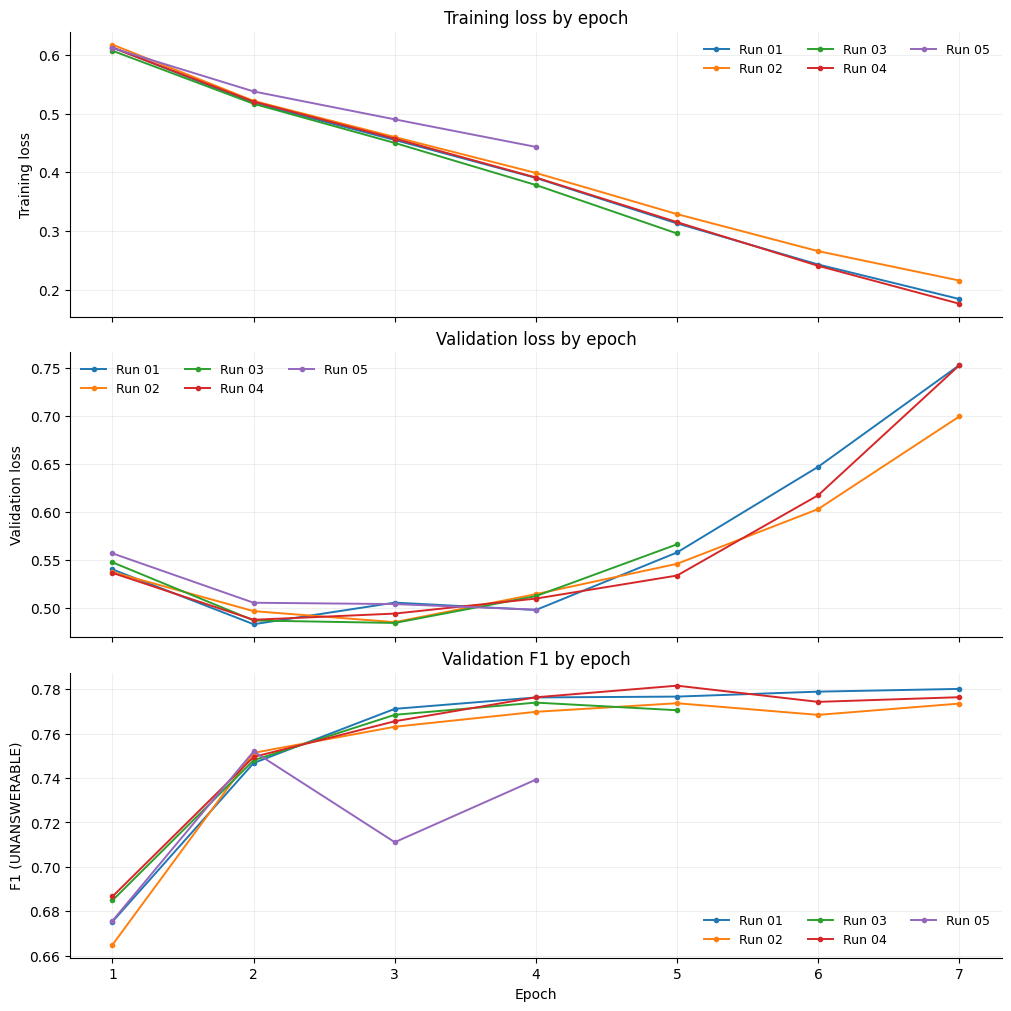

In [4]:
colors = {name: plt.get_cmap('tab10')(i) for i, name in enumerate(runs)}
fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True, layout='constrained')
settings = [('training', 'loss', 'Training loss', 'Training loss by epoch'), ('validation', 'eval_loss', 'Validation loss', 'Validation loss by epoch'), ('validation', 'eval_f1', 'F1 (UNANSWERABLE)', 'Validation F1 by epoch')]
for ax, (event_type, column, ylabel, title) in zip(axes, settings):
    for name, run in runs.items():
        events = run[event_type].sort_values('epoch')
        ax.plot(events['epoch'], events[column], marker='o', markersize=3, linewidth=1.4, color=colors[name], label=run_labels[name])
    ax.set(title=title, ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend(ncol=3, frameon=False, fontsize=9)
    ax.set_xticks(sorted({e for r in runs.values() for e in r['validation']['epoch']}))
axes[-1].set_xlabel('Epoch')
plt.show()

In [5]:
selected = runs[selected_run]
train_events = selected['training'].sort_values('epoch')
val_events = selected['validation'].sort_values('epoch')
min_loss = val_events.loc[val_events['eval_loss'].idxmin()]
run05_events = runs['run_05']['validation'].sort_values('epoch')
display(Markdown(f"For {run_labels[selected_run]}, training loss decreases from **{train_events.iloc[0]['loss']:.4f}** to **{train_events.iloc[-1]['loss']:.4f}**. Validation loss reaches its minimum at epoch **{int(min_loss['epoch'])}** (**{min_loss['eval_loss']:.4f}**) and increases to **{val_events.iloc[-1]['eval_loss']:.4f}** by the end of training. The highest F1 occurs at epoch **{int(selected['best']['epoch'])}**. Loss and F1 therefore favor different checkpoints; the predefined F1 criterion remains decisive."))
display(Markdown(f"Run 05 reaches its highest F1 at epoch **{int(runs['run_05']['best']['epoch'])}** and ends after **{int(run05_events['epoch'].max())}** epochs. Two validations without improvement follow the best checkpoint, consistent with the configured early-stopping patience. The higher-learning-rate experiment does not produce a stronger checkpoint here. The curves alone establish neither a generally optimal learning-rate range nor a specific cause of the decline."))

For Run 04, training loss decreases from **0.6123** to **0.1758**. Validation loss reaches its minimum at epoch **2** (**0.4874**) and increases to **0.7526** by the end of training. The highest F1 occurs at epoch **5**. Loss and F1 therefore favor different checkpoints; the predefined F1 criterion remains decisive.

Run 05 reaches its highest F1 at epoch **2** and ends after **4** epochs. Two validations without improvement follow the best checkpoint, consistent with the configured early-stopping patience. The higher-learning-rate experiment does not produce a stronger checkpoint here. The curves alone establish neither a generally optimal learning-rate range nor a specific cause of the decline.

## 5. Model Selection

Five MathBERT runs were conducted to search for stronger validation performance. Run 04 achieved the highest F1. Experimentation stopped after the substantially weaker fifth run; this is the documented project decision, not evidence of a global optimum. No additional experiments are introduced or presented as completed here.

Selection uses only SUM validation F1 for UNANSWERABLE. SUM test and UMWP do not enter this decision. All runs use the same seed, so robustness across seeds and statistical significance are not established.

In [6]:
if selected_run != 'run_04':
    raise ValueError('The artifacts no longer confirm the recorded selection of Run 04.')
checkpoint_name = Path(runs[selected_run]['report']['best_checkpoint']).name
display(Markdown(f"Selected: **{run_labels[selected_run]}**, checkpoint **{checkpoint_name}**, epoch **{int(runs[selected_run]['best']['epoch'])}**, with validation F1 **{runs[selected_run]['checkpoint_f1']:.6f}**. The saved evaluator `src/17_evaluate_mathbert.py` loads only `models/mathbert/run_04/best_model/`. The original checkpoint directory records provenance; no alternative checkpoint is selected using test results."))

Selected: **Run 04**, checkpoint **checkpoint-7980**, epoch **5**, with validation F1 **0.781577**. The saved evaluator `src/17_evaluate_mathbert.py` loads only `models/mathbert/run_04/best_model/`. The original checkpoint directory records provenance; no alternative checkpoint is selected using test results.

## 6. Test Evaluation

Saved results are loaded from `results/mathbert/run_04/sum_test/` and `results/mathbert/run_04/umwp/`. Metrics come from `metrics.json`; `confusion_matrix.csv` is checked against the JSON matrix. Available `classification_report.json` files provide an additional consistency check. Predictions are not recomputed. Missing core files are reported explicitly rather than replaced with estimated values.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Macro F1
Dataset,,,,,,
SUM test,10944,0.777869,0.785005,0.765351,0.775053,0.777834
UMWP,5200,0.590000,0.594737,0.565000,0.579487,0.589744


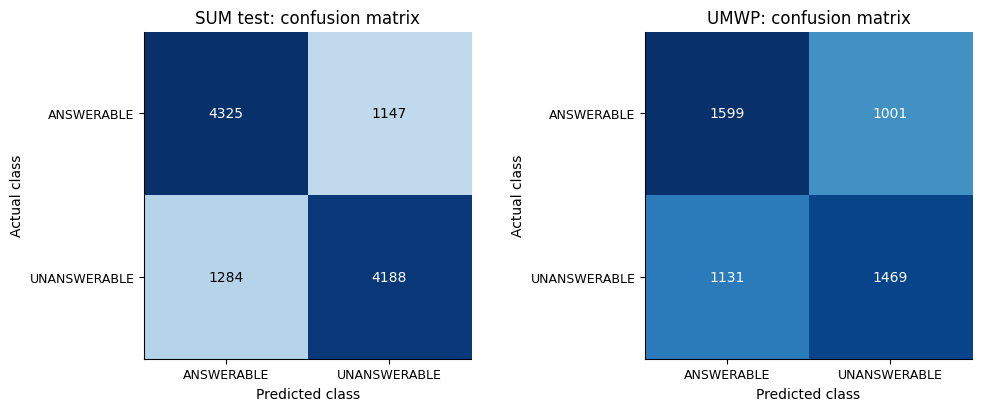

Matrices show absolute counts, with actual classes in rows and predicted classes in columns. Each dataset has its own color scale; because sample sizes differ, colors do not directly measure the performance gap.

In [7]:
evaluation = {}
confusion_matrices = {}
classification_reports = {}
missing_artifacts = []
for folder, dataset_name in [('sum_test', 'SUM test'), ('umwp', 'UMWP')]:
    directory = RESULTS_DIR / selected_run / folder
    required = [directory / 'metrics.json', directory / 'confusion_matrix.csv']
    missing = [str(p.relative_to(PROJECT_ROOT)) for p in required if not p.is_file()]
    if missing:
        missing_artifacts.extend(missing)
        continue
    m = read_json(directory / 'metrics.json')
    if m['selected_run'] != selected_run or m['positive_class'] != 'UNANSWERABLE':
        raise ValueError(f'{folder}: unexpected run or positive class')
    if m.get('model_family') != 'mathbert' or m['confusion_matrix_label_order'] != LABELS:
        raise ValueError(f'{folder}: unexpected model or class order')
    if m['total_examples'] != (10944 if folder == 'sum_test' else 5200):
        raise ValueError(f'{folder}: unexpected number of examples')
    if m['max_length'] != runs[selected_run]['config']['max_length']:
        raise ValueError(f'{folder}: maximum sequence length differs')
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col=0)
    if list(matrix.index) != LABELS or list(matrix.columns) != LABELS:
        raise ValueError(f'{folder}: unexpected confusion-matrix labels')
    if matrix.values.tolist() != m['confusion_matrix'] or int(matrix.values.sum()) != m['total_examples']:
        raise ValueError(f'{folder}: CSV/JSON matrix or total count disagrees')
    report_path = directory / 'classification_report.json'
    if report_path.is_file():
        report = read_json(report_path)
        for report_key, metric_key in [('precision', 'precision_unanswerable'), ('recall', 'recall_unanswerable'), ('f1-score', 'f1_unanswerable')]:
            if not math.isclose(report['UNANSWERABLE'][report_key], m[metric_key], abs_tol=1e-12):
                raise ValueError(f'{folder}: classification report disagrees with metrics.json')
        classification_reports[dataset_name] = report
    else:
        print(f'Additional classification report missing: {report_path.relative_to(PROJECT_ROOT)}')
    evaluation[dataset_name] = m
    confusion_matrices[dataset_name] = matrix
if missing_artifacts:
    display(Markdown('**Missing evaluation artifacts:** ' + ', '.join(missing_artifacts)))
if evaluation:
    test_table = pd.DataFrame([{'Dataset': name, 'Examples': m['total_examples'], 'Accuracy': m['accuracy'], 'Precision (UNANSWERABLE)': m['precision_unanswerable'], 'Recall (UNANSWERABLE)': m['recall_unanswerable'], 'F1 (UNANSWERABLE)': m['f1_unanswerable'], 'Macro F1': m['macro_f1']} for name, m in evaluation.items()]).set_index('Dataset')
    display(test_table.style.format({c: '{:.6f}' for c in test_table.columns if c != 'Examples'}))
    fig, axes = plt.subplots(1, len(evaluation), figsize=(5 * len(evaluation), 4), layout='constrained', squeeze=False)
    for ax, (name, matrix) in zip(axes[0], confusion_matrices.items()):
        ax.imshow(matrix.values, cmap='Blues', vmin=0, vmax=matrix.values.max())
        for row in range(2):
            for col in range(2):
                count = int(matrix.iloc[row, col])
                ax.text(col, row, str(count), ha='center', va='center', color='white' if count > matrix.values.max() / 2 else 'black')
        ax.set_xticks([0, 1], LABELS, fontsize=9)
        ax.set_yticks([0, 1], LABELS, fontsize=9)
        ax.set(title=f'{name}: confusion matrix', xlabel='Predicted class', ylabel='Actual class')
    plt.show()
    display(Markdown('Matrices show absolute counts, with actual classes in rows and predicted classes in columns. Each dataset has its own color scale; because sample sizes differ, colors do not directly measure the performance gap.'))

In [8]:
if 'SUM test' in evaluation:
    sum_metrics = evaluation['SUM test']
    validation_test_gap_pp = 100 * (runs[selected_run]['checkpoint_f1'] - sum_metrics['f1_unanswerable'])
    display(Markdown(f"On SUM test, F1 is **{sum_metrics['f1_unanswerable']:.2%}**, which is **{validation_test_gap_pp:.2f} percentage points** below the selected validation F1. These values come from separate splits. The gap is a descriptive observation, not statistical evidence of a cause."))
if 'SUM test' in evaluation and 'UMWP' in evaluation:
    umwp_metrics = evaluation['UMWP']
    f1_gap_pp = 100 * (sum_metrics['f1_unanswerable'] - umwp_metrics['f1_unanswerable'])
    recall_gap_pp = 100 * (sum_metrics['recall_unanswerable'] - umwp_metrics['recall_unanswerable'])
    false_negatives = int(confusion_matrices['UMWP'].loc['UNANSWERABLE', 'ANSWERABLE'])
    display(Markdown(f"On UMWP, F1 decreases to **{umwp_metrics['f1_unanswerable']:.2%}**, or **{f1_gap_pp:.2f} percentage points** below SUM test. UNANSWERABLE recall is **{umwp_metrics['recall_unanswerable']:.2%}**, which is **{recall_gap_pp:.2f} percentage points** lower. **{false_negatives}** unanswerable problems are classified as answerable. The results show weaker transfer to the external benchmark; they do not isolate differences in task distribution or data quality as individual causes."))
if 'UMWP' in evaluation and 'duplicate_consistency' in evaluation['UMWP']:
    d = evaluation['UMWP']['duplicate_consistency']
    display(Markdown(f"UMWP contains **{d['duplicated_question_texts']}** repeated question texts, including **{d['conflicting_ground_truth_texts']}** with conflicting labels. In **{d['texts_with_inconsistent_predictions']}** groups, predictions differ for identical texts. All official rows are retained; label conflicts limit interpretation of individual errors."))

On SUM test, F1 is **77.51%**, which is **0.65 percentage points** below the selected validation F1. These values come from separate splits. The gap is a descriptive observation, not statistical evidence of a cause.

On UMWP, F1 decreases to **57.95%**, or **19.56 percentage points** below SUM test. UNANSWERABLE recall is **56.50%**, which is **20.04 percentage points** lower. **1131** unanswerable problems are classified as answerable. The results show weaker transfer to the external benchmark; they do not isolate differences in task distribution or data quality as individual causes.

UMWP contains **10** repeated question texts, including **5** with conflicting labels. In **0** groups, predictions differ for identical texts. All official rows are retained; label conflicts limit interpretation of individual errors.

### Limitations of Interpretation

Results use one seed and a limited sequential search over five configurations. They establish neither a global optimum nor statistical significance. A fixed maximum token length does not eliminate possible information loss through truncation. Exact-text isolation of SUM splits does not rule out semantic similarities or overlap with pretraining data. The pretrained revision is not available as an immutable commit in every artifact; absolute training paths record provenance rather than local file availability.

The analysis separates validation-based model selection from interpretation of the saved test results. It changes neither data nor thresholds and derives no new hyperparameters from UMWP.

## 7. Conclusion

In [9]:
summary = f"After five MathBERT runs, **{run_labels[selected_run]}** was selected with validation F1 **{runs[selected_run]['checkpoint_f1']:.2%}** at epoch **{int(runs[selected_run]['best']['epoch'])}**. The substantially weaker fifth run did not change the selection; experimentation then stopped without claiming a global optimum. "
if 'SUM test' in evaluation and 'UMWP' in evaluation:
    summary += f"The selected checkpoint achieves **{sum_metrics['accuracy']:.2%} accuracy** and **{sum_metrics['f1_unanswerable']:.2%} F1** on SUM test, and **{umwp_metrics['accuracy']:.2%} accuracy** and **{umwp_metrics['f1_unanswerable']:.2%} F1** on UMWP. The F1 gap of **{f1_gap_pp:.2f} percentage points** shows limited generalization to the external benchmark; the available artifacts do not isolate its causes."
else:
    summary += 'A complete test interpretation is unavailable because artifacts are missing.'
display(Markdown(summary))

After five MathBERT runs, **Run 04** was selected with validation F1 **78.16%** at epoch **5**. The substantially weaker fifth run did not change the selection; experimentation then stopped without claiming a global optimum. The selected checkpoint achieves **77.79% accuracy** and **77.51% F1** on SUM test, and **59.00% accuracy** and **57.95% F1** on UMWP. The F1 gap of **19.56 percentage points** shows limited generalization to the external benchmark; the available artifacts do not isolate its causes.